# Pearson, Spearman and mutual information: edge planes — 2026-10-20

Fig. 1-style view of the completed 2026-09-24 focused corpus (pyspi computation r7, 50 independent MTS per construction). Nothing is recomputed: z comes from the archived edge profiles.

The construction is a ladder of channel families driven by one AR(1) mother $u$. Channels are $g(u)$ plus independent noise (SD 0.01–0.1 of the unit-variance signal), with $g$ linear (L), sigmoid $1/(1+e^{-\beta u})$ (M) or quadratic $u^2$ (Q). The three recordings types are L (32 channels), L+M (16+16) and L+M+Q (12+12+8); $T=2000$ and $\beta=\pi$ throughout. The same-family pairs (L–L, M–M, Q–Q) are linearly related, L–M pairs are monotone and L–Q/M–Q pairs are non-monotone.

The three statistics are nested by invariance. Pearson $r$ is invariant to affine maps of each channel, Spearman $\rho$ to monotone maps, and MI to any invertible map. MI is shown on the Linfoot scale $\sqrt{1-e^{-2I}}$, which equals $|r|$ for a bivariate Gaussian, so the identity line means agreement in every panel. z on that scale is reported next to the archived raw-MI z.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for p in (ROOT, ROOT / 'src'):
    if str(p) not in sys.path[:2]: sys.path.insert(0, str(p))
from research.cases.refresh_case_figures import analyze
from research.cases import edge_planes as ep
ep.style()
DATA = ROOT / 'data/cases/r-rho-mi-260924/data'
OUT = ROOT / 'results/cases/r-rho-mi-261020'
BETA = 'beta-pi'
frame = analyze(DATA, 'r-rho-mi', OUT)  # validates the 350 archived recordings; never runs pyspi
table = ep.rmi_table(frame)
table.to_csv(OUT / 'z_by_recording.csv', index=False)
cols = ['z_r_rho', 'z_rho_mil', 'z_r_mil', 'z_rho_mi', 'z_r_mi']
summary = table.groupby(['class', 'beta_tag'])[cols].agg(['mean', 'std']).round(3)
summary

z_r_rho        z_rho_mil        z_r_mil        z_rho_mi  \
                       mean    std      mean    std    mean    std     mean   
class      beta_tag                                                           
iter1_L    baseline   1.000  0.000     0.999  0.000   0.999  0.000    0.831   
iter2_LM   beta-2pi   0.270  0.031     0.839  0.066   0.379  0.064    0.830   
           beta-5     0.215  0.036     0.874  0.060   0.337  0.058    0.827   
           beta-pi    0.188  0.065     0.970  0.018   0.292  0.053    0.847   
iter3_LMNM beta-2pi   0.995  0.001     0.481  0.037   0.480  0.043    0.416   
           beta-5     0.996  0.001     0.470  0.045   0.468  0.048    0.446   
           beta-pi    0.998  0.001     0.460  0.064   0.457  0.065    0.491   

                           z_r_mi         
                       std   mean    std  
class      beta_tag                       
iter1_L    baseline  0.039  0.829  0.039  
iter2_LM   beta-2pi  0.037  0.465  0.029  
           beta-5    0.033  0.410  0.031  
           beta-pi   0.030  0.307  0.045  
iter3_LMNM beta-2pi  0.074  0.420  0.078  
           beta-5    0.078  0.448  0.080  
           beta-pi   0.079  0.487  0.078

**Figure.** Each point is a channel pair of one recording (instance 0, chosen in advance). The restrictive statistic is on x and the tolerant one on y; the grey line is the identity. Legends give that recording's z. Insets give z for all 50 recordings of each construction (dots) and their mean (dashed).

(a) Adding sigmoid channels moves L–M pairs above the identity: the sigmoid lowers $r$ but keeps ranks. M–M pairs fall slightly below it, because noise reorders ranks where the sigmoid is flat. (b) Adding quadratic channels moves L–Q and M–Q pairs to $\rho\approx0$ while MI stays high. The L+M recording's pairs stay on the identity, so ρ and MI agree on monotone pairs.

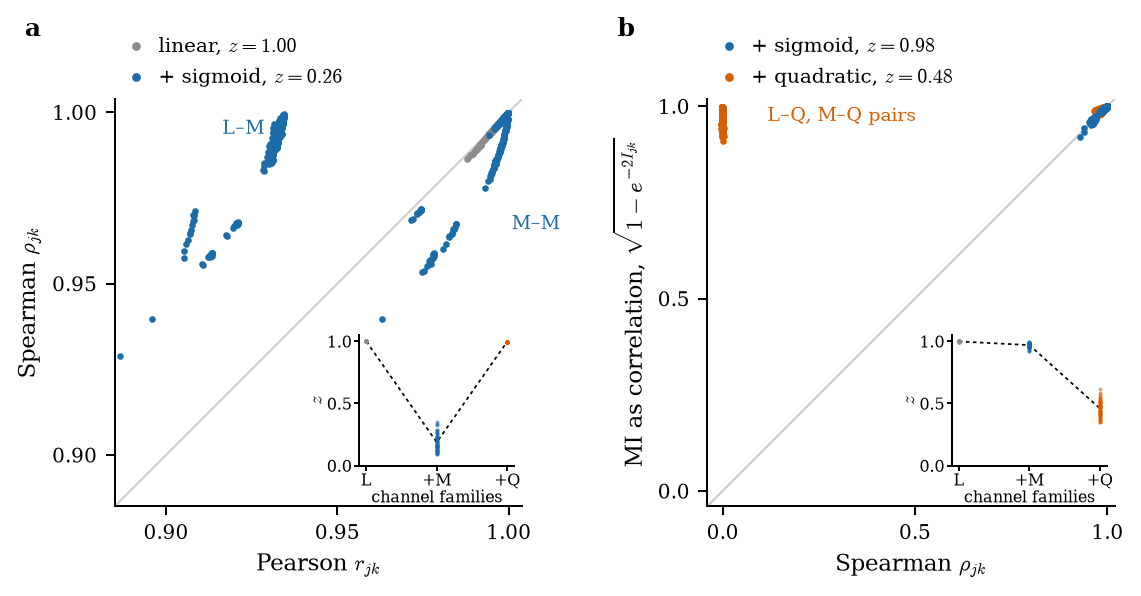

In [2]:
fig = ep.plot_rmi(frame, table, beta_tag=BETA)
ep.save(fig, OUT, 'r-rho-mi_edge-planes')
plt.show()

## Checks

1. Raw MI against the Linfoot scale. Under Gaussianity MI is a fixed convex function of $r$, $-\tfrac12\ln(1-r^2)$. Pearson aggregation of raw MI therefore falls below 1 in a purely linear recording, by an amount set by the spread of pair strengths.
2. The return of $z_{r,\rho}$ at +Q. Restrict both profiles to the L–M pairs, which are present in both mixtures.
3. Sensitivity to β (all three archived values).
4. Mean offsets by pair type.

In [3]:
lin = table[table['class'] == 'iter1_L']
gauss = []
for path in frame[frame['class'] == 'iter1_L'].path:
    p, _ = ep.bank(path)
    gauss.append(ep.z(-0.5 * np.log1p(-p[ep.R] ** 2), p[ep.MI]))
print(f"L recordings: z(r, MI raw) = {lin.z_r_mi.mean():.3f} ± {lin.z_r_mi.std():.3f}; "
      f"z(r, MI Linfoot) = {lin.z_r_mil.mean():.4f}; z(Gaussian MI of r, MI) = {np.mean(gauss):.4f} (min {np.min(gauss):.4f})")
sel = table[(table.beta_tag == BETA) | (table['class'] == 'iter1_L')]
print('z(r, rho) on L–M pairs only:', sel.groupby('class').z_r_rho_LM_only.agg(['mean', 'std']).round(3).dropna().to_dict('index'))

L recordings: z(r, MI raw) = 0.829 ± 0.039; z(r, MI Linfoot) = 0.9994; z(Gaussian MI of r, MI) = 0.9997 (min 0.9996)
z(r, rho) on L–M pairs only: {'iter2_LM': {'mean': 0.931, 'std': 0.036}, 'iter3_LMNM': {'mean': 0.934, 'std': 0.054}}


In [4]:
rows = []
for _, rec in frame[(frame.beta_tag == BETA) | (frame['class'] == 'iter1_L')].iterrows():
    p, meta = ep.bank(rec.path)
    types = np.array(meta['generator']['types'])
    iu = np.triu_indices(len(types), 1)
    kind = np.array(['–'.join(sorted((a[0].upper() if a != 'non-monotonic' else 'Q', b[0].upper() if b != 'non-monotonic' else 'Q')))
                     for a, b in zip(types[iu[0]], types[iu[1]])])
    for k in np.unique(kind):
        m = kind == k
        rows.append({'class': rec['class'], 'pair': k, 'r': p[ep.R][m].mean(), 'rho': p[ep.RHO][m].mean(),
                     'MI Linfoot': ep.linfoot(p[ep.MI][m]).mean(), 'rho - r': (p[ep.RHO][m] - p[ep.R][m]).mean(),
                     'MI Linfoot - rho': (ep.linfoot(p[ep.MI][m]) - p[ep.RHO][m]).mean()})
pairs = pd.DataFrame(rows).groupby(['class', 'pair']).mean().round(4)
pairs

r     rho  MI Linfoot  rho - r  MI Linfoot - rho
class      pair                                                       
iter1_L    L–L   0.9953  0.9948      0.9955  -0.0006            0.0007
iter2_LM   L–L   0.9953  0.9947      0.9954  -0.0005            0.0007
           L–M   0.9299  0.9904      0.9909   0.0605            0.0005
           M–M   0.9954  0.9872      0.9907  -0.0082            0.0035
iter3_LMNM L–L   0.9958  0.9954      0.9960  -0.0005            0.0006
           L–M   0.9299  0.9905      0.9911   0.0606            0.0006
           L–Q  -0.0002 -0.0001      0.9840   0.0000            0.9842
           M–M   0.9953  0.9868      0.9904  -0.0085            0.0036
           M–Q  -0.0005 -0.0002      0.9527   0.0003            0.9529
           Q–Q   0.9951  0.9588      0.9858  -0.0362            0.0270

In [5]:
def ms(s): return {'mean': round(float(s.mean()), 4), 'sd': round(float(s.std()), 4), 'n': int(len(s))}
out = {'source': 'data/cases/r-rho-mi-260924 (pyspi r7, archived; not recomputed)', 'beta_figure': BETA,
       'figure_instance': 0, 'mi_scale_in_figure': 'Linfoot sqrt(1-exp(-2 MI))',
       'z': {f'{c}|{b}': {k: ms(g[k]) for k in cols + ['z_r_rho_LM_only']} for (c, b), g in table.groupby(['class', 'beta_tag'])},
       'linear_baseline_gaussian_mi_z': {'mean': round(float(np.mean(gauss)), 5), 'min': round(float(np.min(gauss)), 5)},
       'pair_type_means': {f'{c}|{p}': row.to_dict() for (c, p), row in pairs.iterrows()}}
(OUT / 'summary.json').write_text(json.dumps(out, indent=1) + '\n')
print('wrote', (OUT / 'summary.json').relative_to(ROOT))

wrote results/cases/r-rho-mi-261020/summary.json


## Interpretation

**{r, ρ}: monotone nonlinearity, only when no non-monotone pairs are present.** z falls from 1.000 (L) to 0.19 ± 0.07 (L+M), with no overlap between the 50 + 50 recordings. L–M pairs lose 0.065 in r but nothing in ρ, so the group offset that dominates the r profile is missing from the ρ profile. Within the L–M pairs alone, r and ρ still agree (z = 0.93). M–M pairs add a smaller offset the other way (ρ − r = −0.008), from noise in the sigmoid's flat tails. Adding quadratic channels restores z to 0.998 although the L–M offset is unchanged (within-L–M z = 0.93 in both mixtures). The L–Q and M–Q pairs at r ≈ ρ ≈ 0 form a second cluster whose spread dominates both profiles. Read alone, z(r, ρ) is therefore U-shaped along the ladder: a strong effect with a conditional reading.

**{ρ, MI}: non-monotone dependence.** On the Linfoot scale z is 0.999 (L), 0.970 ± 0.018 (L+M) and 0.46 ± 0.06 (L+M+Q). ρ and Linfoot MI agree on L–M pairs to 5 × 10⁻⁴, so the monotone step barely moves z. L–Q and M–Q pairs have ρ ≈ 0 but Linfoot MI of 0.95–0.98, which breaks it. This is the cleanest single-pair reading in the case. On raw MI the change runs 0.83 → 0.85 → 0.49: the same direction from a lower reference.

**{r, MI}: linear versus general.** z goes 0.999 → 0.29 → 0.46 (Linfoot; raw 0.83 → 0.31 → 0.49). As the union of the other two pairs, it drops at both steps. It does not order them: the monotone step drops it further than the non-monotone one. It carries no information about which step occurred.

**Triplet.** The vector (z_rρ, z_ρI, z_rI) is (1.00, 1.00, 1.00) for L, (0.19, 0.97, 0.29) for L+M and (1.00, 0.46, 0.46) for L+M+Q. The odd one out identifies the step: r for monotone, MI for non-monotone. This matches the nested-axes reading, with one correction. In z-space the non-monotone signature is "r and ρ agree with each other and disagree with MI", not "r and ρ low". The reading needs MI on the Linfoot scale; on raw MI the all-agree reference is (1.00, 0.83, 0.83).

**Scope.** Every channel is a near-noiseless function (noise SD 0.01–0.1) of one shared latent, and non-Q pairs span only r ≈ 0.88–1.0. The case shows which families coexist in a recording, not a graded degree of nonlinearity. β matters: z_ρI at L+M is 0.97, 0.87 and 0.84 at β = π, 5 and 2π, as saturation and noise erode MI's invariance. β = π is the cleanest archived value.

## Flags

- **MI scale.** In purely linear recordings, raw-MI z is 0.83 ± 0.04, while z between KSG MI and the Gaussian MI implied by r is 0.9997. The shortfall is MI's convexity in r, weighted by how pair strength is spread. That is the Nolte et al. (2020) point in concrete form, not character. Put MI on the Linfoot scale (or another Gaussian-calibrated scale) before z, or report z against a strength-matched Gaussian surrogate. The archived coordinate is raw MI; this figure uses Linfoot.
- **Confusing condition.** In the +Q mixture, Q-cross pairs restore z(r, ρ), so L+M+Q confounds the {r, ρ} reading. An L+Q construction without L–M pairs would isolate the non-monotone step; otherwise read only the triplet.
- **Noise × transform artefact.** Same-family nonlinear pairs sit below the identity: ρ − r is −0.008 for M–M and −0.036 for Q–Q, because noise reorders ranks where the transform is flat. Part of the +M drop is this effect, not monotone character.
- **Over-reach.** "z(r, ρ) measures monotone nonlinearity" is not supported. The design is near-saturated (non-Q r ≥ 0.88, a 0.07-wide range) and shows discrete family composition only.
- **Redundant pair.** {r, MI} adds no step information beyond the adjacent pairs. It is a candidate to drop from figures, not from the feature set. The DCE-AUTO MI variant moves z by at most 0.01 (archived audit) and is also redundant here.
- **Overlap with Fig. 1.** Spearman is Fig. 1's zero-lag control (z = 0.997 in both families). See the rationalisation note in the DTW viewer.